# Assignment 61 — Week 7, Day 1
## Topic: Deep Learning — Text Processing with NLTK

**Objective:** Complete the text-processing exercise.

**Reference:** https://pythonspot.com/category/nltk/

The Natural Language Toolkit (**NLTK**) is a Python library for processing human language. The pythonspot NLTK series covers the core text-processing tasks, which this notebook works through in order:

1. Tokenising words and sentences
2. Removing stop words
3. Stemming
4. Part-of-speech (speech) tagging
5. Sentiment analysis with a classifier
6. Prediction: guessing gender from a name

**Requirements:** `pip install nltk`, then the data packages downloaded in the first cell.

**Download the NLTK data**

In [1]:
import nltk

for package in ["punkt", "punkt_tab", "stopwords", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
                "names", "movie_reviews"]:
    nltk.download(package, quiet=True)

print("NLTK", nltk.__version__, "ready")

NLTK 3.10.3 ready


**Explanation:** The tokeniser, stop word list, tagger and the names and movie review corpora are downloaded once.

**Diagram:** How the same sentence changes at each processing step.

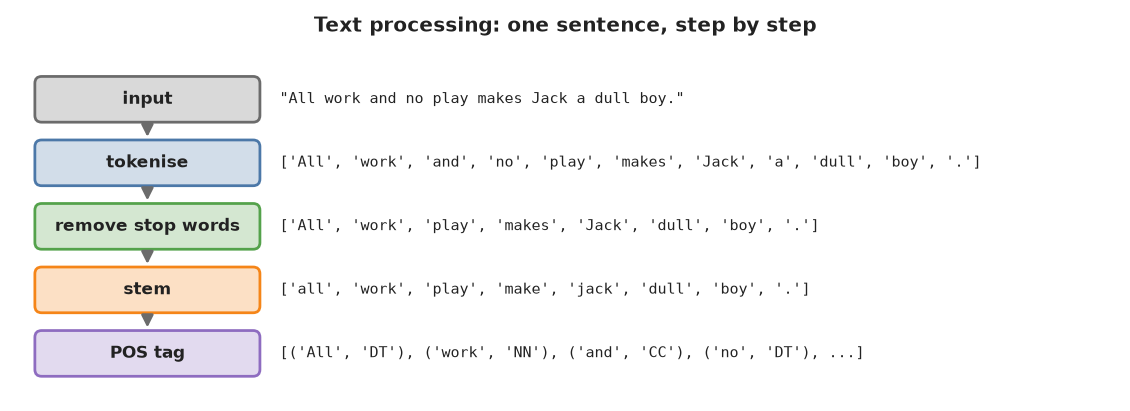

## 1. Tokenising

**Tokenise words**

In [2]:
from nltk.tokenize import word_tokenize

data = "All work and no play makes jack a dull boy, all work and no play"
print(word_tokenize(data))

['All', 'work', 'and', 'no', 'play', 'makes', 'jack', 'a', 'dull', 'boy', ',', 'all', 'work', 'and', 'no', 'play']


**Explanation:** word_tokenize() splits the text into words and punctuation marks (tokens).

**Tokenise sentences**

In [3]:
from nltk.tokenize import sent_tokenize

data = "All work and no play makes jack dull boy. All work and no play makes jack a dull boy."
print(sent_tokenize(data))

['All work and no play makes jack dull boy.', 'All work and no play makes jack a dull boy.']


**Explanation:** sent_tokenize() splits text into sentences, using punctuation and capital letters as clues.

**Store words and sentences in lists**

In [4]:
from nltk.tokenize import sent_tokenize, word_tokenize

data = "All work and no play makes jack dull boy. All work and no play makes jack a dull boy."

phrases = sent_tokenize(data)
words = word_tokenize(data)

print(phrases)
print(words)
print("Unique words:", sorted(set(w.lower() for w in words if w.isalpha())))

['All work and no play makes jack dull boy.', 'All work and no play makes jack a dull boy.']
['All', 'work', 'and', 'no', 'play', 'makes', 'jack', 'dull', 'boy', '.', 'All', 'work', 'and', 'no', 'play', 'makes', 'jack', 'a', 'dull', 'boy', '.']
Unique words: ['a', 'all', 'and', 'boy', 'dull', 'jack', 'makes', 'no', 'play', 'work']


**Explanation:** The tokens are ordinary Python lists, so they can be counted, filtered or turned into a set of unique words.

## 2. Stop words

**Remove stop words**

In [5]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

data = "All work and no play makes jack dull boy. All work and no play makes jack a dull boy."
stopWords = set(stopwords.words("english"))
words = word_tokenize(data)

wordsFiltered = [w for w in words if w not in stopWords]

print(wordsFiltered)
print(len(stopWords), "English stop words, e.g.", sorted(stopWords)[:10])

['All', 'work', 'play', 'makes', 'jack', 'dull', 'boy', '.', 'All', 'work', 'play', 'makes', 'jack', 'dull', 'boy', '.']
198 English stop words, e.g. ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']


**Explanation:** Stop words such as 'and', 'no' and 'a' appear in almost every sentence and add little meaning, so they are removed. Note that 'All' is kept because the check is case-sensitive; lower-casing first would remove it too.

## 3. Stemming

**Stem a list of words**

In [6]:
from nltk.stem import PorterStemmer

words = ["game", "gaming", "gamed", "games"]
ps = PorterStemmer()

for word in words:
    print(word, "->", ps.stem(word))

game -> game
gaming -> game
gamed -> game
games -> game


**Explanation:** A stemmer reduces related words to the same root, so 'gaming', 'gamed' and 'games' all become 'game'. This lets a program treat them as one word.

**Stem every word of a sentence**

In [7]:
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

ps = PorterStemmer()
sentence = "gaming, the gamers play games"

print([ps.stem(w) for w in word_tokenize(sentence)])

['game', ',', 'the', 'gamer', 'play', 'game']


**Explanation:** Combining the tokeniser and the stemmer stems a whole sentence. 'gamers' becomes 'gamer', since the stemmer only removes certain endings.

## 4. Speech (part-of-speech) tagging

**Tag the words of a sentence**

In [8]:
import nltk
from nltk.tokenize import word_tokenize

document = "Whether you're new to programming or an experienced developer, it's easy to learn and use Python."
tokens = word_tokenize(document)

print(nltk.pos_tag(tokens))

[('Whether', 'IN'), ('you', 'PRP'), ("'re", 'VBP'), ('new', 'JJ'), ('to', 'TO'), ('programming', 'VBG'), ('or', 'CC'), ('an', 'DT'), ('experienced', 'JJ'), ('developer', 'NN'), (',', ','), ('it', 'PRP'), ("'s", 'VBZ'), ('easy', 'JJ'), ('to', 'TO'), ('learn', 'VB'), ('and', 'CC'), ('use', 'VB'), ('Python', 'NNP'), ('.', '.')]


**Explanation:** pos_tag() gives each word a grammatical tag, such as NN (noun), VB (verb), JJ (adjective) and PRP (pronoun).

**Filter words by their tag**

In [9]:
import nltk
from nltk.tokenize import word_tokenize

document = "Whether you're new to programming or an experienced developer, it's easy to learn and use Python."
tagged = nltk.pos_tag(word_tokenize(document))

nouns = [w for w, t in tagged if t.startswith("NN")]
verbs = [w for w, t in tagged if t.startswith("VB")]
adjectives = [w for w, t in tagged if t.startswith("JJ")]

print("Nouns:", nouns)
print("Verbs:", verbs)
print("Adjectives:", adjectives)

Nouns: ['developer', 'Python']
Verbs: ["'re", 'programming', "'s", 'learn', 'use']
Adjectives: ['new', 'experienced', 'easy']


**Explanation:** Tags make it easy to pull out one kind of word, for example all the nouns to find what a text is about.

## 5. Sentiment analysis

**Diagram:** Text is turned into word features, which a trained classifier maps to a label.

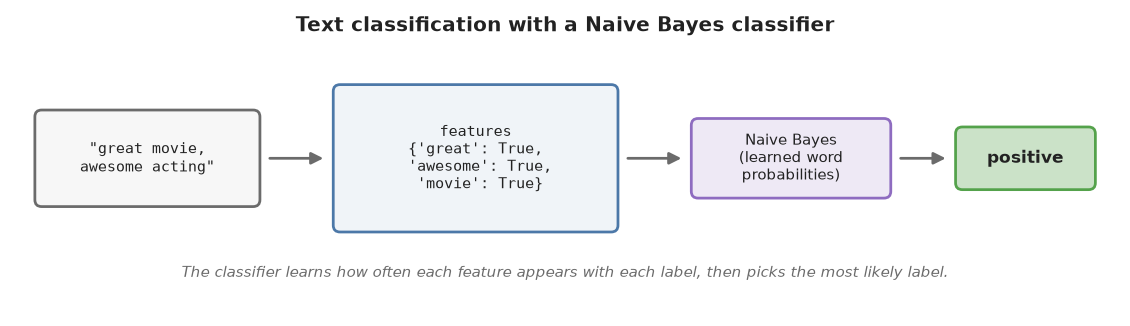

**A simple sentiment classifier (pythonspot method)**

In [10]:
import nltk.classify.util
from nltk.classify import NaiveBayesClassifier

def word_feats(words):
    return dict([(word, True) for word in words])

positive_vocab = ["awesome", "outstanding", "fantastic", "terrific", "good", "nice", "great", ":)"]
negative_vocab = ["bad", "terrible", "useless", "hate", ":("]
neutral_vocab = ["movie", "the", "sound", "was", "is", "actors", "did", "know", "words", "not"]

positive_features = [(word_feats(pos), "pos") for pos in positive_vocab]
negative_features = [(word_feats(neg), "neg") for neg in negative_vocab]
neutral_features = [(word_feats(neu), "neu") for neu in neutral_vocab]

train_set = negative_features + positive_features + neutral_features
classifier = NaiveBayesClassifier.train(train_set)

sentence = "Awesome movie, I liked it"
neg = pos = 0
for word in sentence.lower().split(" "):
    classResult = classifier.classify(word_feats(word))
    if classResult == "neg":
        neg += 1
    if classResult == "pos":
        pos += 1

print("Positive:", pos / len(sentence.split()))
print("Negative:", neg / len(sentence.split()))

Positive: 0.6
Negative: 0.2


**Explanation:** This is the pythonspot approach: a Naive Bayes classifier is trained on small lists of positive, negative and neutral words, then each word of a new sentence is classified. Because word_feats() is given a string, its features are single letters, so the method is very rough; the next example trains on real reviews instead.

**Sentiment analysis trained on real movie reviews**

In [11]:
import random
import nltk
from nltk.corpus import movie_reviews, stopwords
from nltk.classify import NaiveBayesClassifier

stop_words = set(stopwords.words("english"))

def review_features(words):
    return {w.lower(): True for w in words if w.isalpha() and w.lower() not in stop_words}

documents = [(review_features(movie_reviews.words(fid)), category)
             for category in movie_reviews.categories()
             for fid in movie_reviews.fileids(category)]
random.seed(1)
random.shuffle(documents)

train_set, test_set = documents[:1600], documents[1600:]
classifier = NaiveBayesClassifier.train(train_set)

print("Accuracy:", round(nltk.classify.accuracy(classifier, test_set), 3))
classifier.show_most_informative_features(8)

for review in ["The acting was brilliant and the story was wonderful",
               "A boring, stupid film with terrible acting"]:
    print(review, "->", classifier.classify(review_features(review.split())))

Accuracy: 0.693
Most Informative Features


               insulting = True              neg : pos    =     15.5 : 1.0
               maintains = True              pos : neg    =     12.5 : 1.0
            effortlessly = True              pos : neg    =     11.8 : 1.0
               laughably = True              neg : pos    =     11.6 : 1.0
             outstanding = True              pos : neg    =     11.3 : 1.0
                backdrop = True              pos : neg    =     11.1 : 1.0
               stupidity = True              neg : pos    =     10.9 : 1.0
           unintentional = True              neg : pos    =     10.9 : 1.0
The acting was brilliant and the story was wonderful -> pos
A boring, stupid film with terrible acting -> neg


**Explanation:** The movie_reviews corpus has 2000 reviews labelled positive or negative. Each review becomes a set of word features, and Naive Bayes learns which words point to each label. The most informative features show words that strongly suggest one sentiment.

## 6. Prediction: gender from a name

**Train a classifier on name endings**

In [12]:
import random
import nltk
from nltk.corpus import names

def gender_features(word):
    return {"last_letter": word[-1].lower(), "last_two": word[-2:].lower()}

labeled_names = ([(name, "male") for name in names.words("male.txt")] +
                 [(name, "female") for name in names.words("female.txt")])
random.seed(0)
random.shuffle(labeled_names)

featuresets = [(gender_features(n), gender) for (n, gender) in labeled_names]
train_set, test_set = featuresets[500:], featuresets[:500]
classifier = nltk.NaiveBayesClassifier.train(train_set)

print("Accuracy:", round(nltk.classify.accuracy(classifier, test_set), 3))
for name in ["Ali", "Sara", "Ahmed", "Fatima", "Bilal", "Ayesha"]:
    print(name, "->", classifier.classify(gender_features(name)))

Accuracy: 0.798
Ali -> female
Sara -> female
Ahmed -> male
Fatima -> female
Bilal -> male
Ayesha -> female


**Explanation:** A name's last letters are a strong clue to gender in English names (for example, names ending in 'a' are often female). The classifier learns these patterns from about 7,900 labelled names and predicts new ones, though names from other languages may be harder for it.

## Observation

- word_tokenize() and sent_tokenize() split text into words and sentences.
- Stop words are very common words that are usually removed before analysis.
- Stemming reduces related words to one root, such as gaming, gamed and games → game.
- pos_tag() labels each word's part of speech, which can be used to filter nouns, verbs or adjectives.
- A Naive Bayes classifier learns which word features predict a label: the simple vocabulary method is rough, while training on real movie reviews gives about 70% accuracy.
- The same approach predicts gender from the endings of names.

## Conclusion

NLTK provides the basic text-processing tools in a few lines each. Tokenising, cleaning, stemming and tagging prepare text for classifiers that can then predict things such as sentiment or gender.